In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.naive_bayes import CategoricalNB

from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score,precision_score, confusion_matrix,recall_score,ConfusionMatrixDisplay

from sklearn.dummy import DummyClassifier

random_state = 42

## A)  Examiner et partitionner les données 
Chargez les données avec pandas. Interprétez ? comme une valeur manquante, indiquez le nombre de valeurs manquantes 
par caractéristique ainsi que les effectifs des classes, puis séparez les variables prédictives de la variable cible. Effectuez 
une partition stratifiée en ensembles d’entraînement et de test selon un rapport de 80/20, avec random_state=42, avant 
d’ajuster toute étape de prétraitement

In [2]:
df = pd.read_csv('breast-cancer.data', 
                 delimiter=',', 
                 encoding='utf-8',
                 names=["class",
                        "age",
                        "menopause",
                        "tumor-size",
                        "inv-nodes",
                        "node-caps",
                        "deg-malig",
                        "breast",
                        "breast-quad",
                        "irradiat"])

In [3]:
df.head()

,class,age,menopause,tumor-size,inv-nodes,node-caps,deg-malig,breast,breast-quad,irradiat
0,no-recurrence-events,30-39,premeno,30-34,0-2,no,3,left,left_low,no
1,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,right,right_up,no
2,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,left,left_low,no
3,no-recurrence-events,60-69,ge40,15-19,0-2,no,2,right,left_up,no
4,no-recurrence-events,40-49,premeno,0-4,0-2,no,2,right,right_low,no


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 286 entries, 0 to 285
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   class        286 non-null    str  
 1   age          286 non-null    str  
 2   menopause    286 non-null    str  
 3   tumor-size   286 non-null    str  
 4   inv-nodes    286 non-null    str  
 5   node-caps    286 non-null    str  
 6   deg-malig    286 non-null    int64
 7   breast       286 non-null    str  
 8   breast-quad  286 non-null    str  
 9   irradiat     286 non-null    str  
dtypes: int64(1), str(9)
memory usage: 22.5 KB


In [5]:
df = df.replace('?', np.nan)
print(f"Nombre de données manquantes : {df.isna().sum().sum()}")

df.isna().sum().to_frame().T

Nombre de données manquantes : 9


,class,age,menopause,tumor-size,inv-nodes,node-caps,deg-malig,breast,breast-quad,irradiat
0,0,0,0,0,0,8,0,0,1,0


In [6]:
X = df.drop(columns=['class'])
y = df['class']
print("les effectifs des classes", y.value_counts())

les effectifs des classes class
no-recurrence-events    201
recurrence-events        85
Name: count, dtype: int64


In [7]:
X.head()

,age,menopause,tumor-size,inv-nodes,node-caps,deg-malig,breast,breast-quad,irradiat
0,30-39,premeno,30-34,0-2,no,3,left,left_low,no
1,40-49,premeno,20-24,0-2,no,2,right,right_up,no
2,40-49,premeno,20-24,0-2,no,2,left,left_low,no
3,60-69,ge40,15-19,0-2,no,2,right,left_up,no
4,40-49,premeno,0-4,0-2,no,2,right,right_low,no


In [8]:
y.head()

0    no-recurrence-events
1    no-recurrence-events
2    no-recurrence-events
3    no-recurrence-events
4    no-recurrence-events
Name: class, dtype: str

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=random_state, stratify=y)

## B)  Prétraiter les données et entraîner le modèle 
Construisez un Pipeline qui impute les valeurs manquantes à l’aide du mode de chaque colonne de l’ensemble 
d’entraînement, encode les catégories sous forme d’identifiants entiers non négatifs et ajuste CategoricalNB(alpha=1.0). 
Utilisez SimpleImputer et OrdinalEncoder. Assurez-vous que les catégories valides absentes de l’ensemble d’entraînement 
puissent tout de même être traitées lors de la prédiction. N’ajustez pas l’imputeur et ne déterminez pas les catégories à 
partir de l’ensemble de test

In [10]:
X.columns

Index(['age', 'menopause', 'tumor-size', 'inv-nodes', 'node-caps', 'deg-malig',
       'breast', 'breast-quad', 'irradiat'],
      dtype='str')

In [11]:
categories = [
    ["10-19", "20-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80-89", "90-99"],
    [ "lt40", "ge40", "premeno"],
    ["0-4", "5-9", "10-14", "15-19", "20-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54", "55-59"],
    ["0-2", "3-5", "6-8", "9-11", "12-14", "15-17", "18-20", "21-23", "24-26", "27-29", "30-32", "33-35", "36-39"],
    ["yes", "no"],
    [1, 2, 3],
    ["left", "right"],
    ["left_up", "left_low", "right_up", "right_low", "central"],
    ["yes", "no"]
]

In [12]:
pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(categories=categories)),
    ('classifier', CategoricalNB(alpha=1.0,
                                  min_categories=[len(c) for c in categories]))
])

In [13]:
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('encoder', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[<U20](2,)","['no-recurrence-events','recurrence-events']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['age','menopause','tumor-size',...,'breast','breast-quad','irradiat']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'most_frequent'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurre

## C)  Évaluer 
Sur l’ensemble de test réservé à l’évaluation, indiquez l’exactitude (accuracy), l’exactitude équilibrée (balanced accuracy), la 
précision, le rappel et le score F1 pour la classe de récidive, ainsi qu’une matrice de confusion avec les libellés des classes. 
Comparez l’exactitude et l’exactitude équilibrée à celles de DummyClassifier(strategy="most_frequent") ajusté sur 
l’ensemble d’entraînement. Conservez la même partition des données pour les deux modèles. 

Accuracy: 0.7241
Balanced Accuracy: 0.6327
Precision: 0.5385
Recall: 0.4118
F1 Score: 0.4667


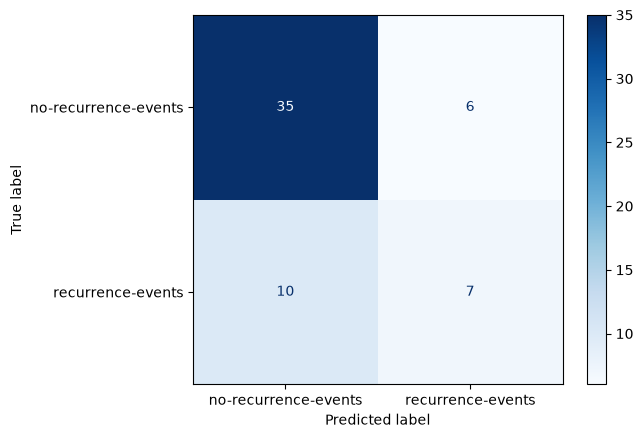

In [14]:
y_pred = pipeline.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
balanced_accuracy = balanced_accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label='recurrence-events')
recall = recall_score(y_test, y_pred, pos_label='recurrence-events')
f1 = f1_score(y_test, y_pred, pos_label='recurrence-events')
matrix_confusion = confusion_matrix(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Balanced Accuracy: {balanced_accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

disp = ConfusionMatrixDisplay(confusion_matrix=matrix_confusion, display_labels=pipeline.classes_)
disp.plot(cmap=plt.cm.Blues)


In [15]:
dummy_clf = DummyClassifier(strategy="most_frequent")
dummy_clf.fit(X_train, y_train)

dummy_pred = dummy_clf.predict(X_test)
dummy_accuracy = accuracy_score(y_test, dummy_pred)
print(f"Dummy Classifier Accuracy: {dummy_accuracy:.4f}")   
print(f"Dummy Classifier Balanced Accuracy: {balanced_accuracy_score(y_test, dummy_pred):.4f}")

Dummy Classifier Accuracy: 0.7069
Dummy Classifier Balanced Accuracy: 0.5000


In [16]:
results = pd.DataFrame({
    "Model": ["CategoricalNB", "DummyClassifier"],
    "Accuracy": [
        accuracy,
        dummy_accuracy
    ],
    "Balanced Accuracy": [
        balanced_accuracy,
        balanced_accuracy_score(y_test, dummy_pred)
    ],
})

print(results)

             Model  Accuracy  Balanced Accuracy
0    CategoricalNB  0.724138           0.632712
1  DummyClassifier  0.706897           0.500000


## D)  Expliquer 
En 100 à 150 mots, justifiez l’utilisation de CategoricalNB pour ces caractéristiques, expliquez comment votre prétraitement 
évite la fuite de données et discutez des raisons pour lesquelles l’exactitude seule peut être trompeuse. Interprétez le rappel 
de la classe de récidive et décrivez une limite de l’hypothèse d’indépendance du modèle bayésien naïf. 
Indication pour l’encodage : Vous pouvez définir l’ensemble complet des catégories à partir des métadonnées publiées par 
l’UCI à l’aide de OrdinalEncoder(categories=...). Définissez CategoricalNB(min_categories=...) en fonction du nombre de 
catégories de chaque caractéristique, afin que des entrées de probabilité soient également allouées aux catégories 
absentes de l’ensemble d’entraînement. Veillez à la cohérence des types des catégories ; les codes négatifs ne sont pas 
valides pour CategoricalNB. 

Réponse:
1. CategoricalNB est adapté à ce jeu de données, car les neuf caractéristiques sont catégorielles. Il estime les probabilités des catégories pour prédire la récidive.

2. Nous séparons les données avant le prétraitement. L’imputation est ajustée uniquement sur l’ensemble d’entraînement, tandis que les catégories sont définies à partir des métadonnées UCI. Le paramètre min_categories prévoit les catégories absentes de l’entraînement.

3. Les classes étant déséquilibrées, l’exactitude seule peut être trompeuse : le modèle obtient 72,41 %, contre 70,69 % pour DummyClassifier, mais son exactitude équilibrée atteint 63,27 %, contre 50 %.

4. Le rappel de la récidive est de 0,41 : environ 59 % des récidives ne sont pas détectées.

5. CategoricalNB suppose l’indépendance conditionnelle des caractéristiques, une hypothèse parfois irréaliste lorsque certaines variables médicales sont corrélées.